# Oil Palm Fruit Ripeness Grading — Experimental Notebook
**Working method:** Uncertainty-Conditioned Feature Fusion in a Lightweight Hybrid CNN–Transformer  
**Framework:** PyTorch | **Input:** 224×224 | **Batch size:** 16 | **Seed:** 42

> Run cells from top to bottom. Set `DATA_ROOT` in Cell 4 to the extracted Roboflow classification dataset directory. This notebook expects class-subfolder structure (for example `train/Ripe/*.jpg`, `valid/Ripe/*.jpg`, `test/Ripe/*.jpg`, or one root folder containing class subfolders).
>
> Models are saved outside the notebook. Figures, tables, metrics, and experiment logs are displayed in this notebook.

In [3]:
pip install --upgrade pip

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   -------------------------------- ------- 1.6/2.0 MB 9.3 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 7.7 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 25.1.1
    Uninstalling pip-25.1.1:
      Successfully uninstalled pip-25.1.1
Note: you may need to restart the kernel to use updated packages.


## Part 0 — Environment and configuration

In [29]:
# If packages are missing, uncomment and run this cell once.
# %pip install -q torch torchvision torchaudio scikit-learn pandas numpy matplotlib seaborn pillow tqdm

import os, sys, gc, json, time, copy, random, hashlib, warnings, platform
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Ensure PyTorch is available in the current notebook kernel.
try:
    import torch
except ModuleNotFoundError:
    import subprocess, sys
    print("PyTorch not found. Installing in the active environment...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "torch", "torchvision", "torchaudio", "scikit-learn",
        "pandas", "numpy", "matplotlib", "seaborn", "pillow", "tqdm"
    ])
    import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
    balanced_accuracy_score, cohen_kappa_score
)
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
plt.style.use("default")
sns.set_context("notebook")

In [30]:
# Research configuration — fixed before the final test evaluation.
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0                 # Safer default for Windows/Jupyter; increase to 2 only if stable.
EPOCHS = 20                     # Preliminary setting; tune using validation only.
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5
NUM_CLASSES = 4
CLASS_NAMES_EXPECTED = ["Unripe", "Underripe", "Ripe", "Overripe"]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
PIN_MEMORY = DEVICE.type == "cuda"

PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "dataset" / "oil_palm_fruit"  # EDIT if needed
OUTPUT_ROOT = PROJECT_ROOT / "results"
MODEL_ROOT = PROJECT_ROOT / "models"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MODEL_ROOT.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("AMP:", USE_AMP)
print("Dataset path:", DATA_ROOT.resolve())

Device: cpu
AMP: False
Dataset path: D:\S2\Research\OilPalm_Research\dataset\oil_palm_fruit


In [31]:
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Deterministic mode can reduce speed; enabled for reproducibility.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("Total VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
    print("PyTorch CUDA:", torch.version.cuda)
else:
    print("CUDA GPU not detected. Training will use CPU.")

CUDA GPU not detected. Training will use CPU.


## Part 1 — Dataset audit and preprocessing

### Cell 4 — Dataset path and class mapping

Expected Roboflow classification layouts:
- `DATA_ROOT/train/<class_name>/image.jpg`, `DATA_ROOT/valid/<class_name>/...`, `DATA_ROOT/test/<class_name>/...`; or
- `DATA_ROOT/<class_name>/image.jpg`.

If the downloaded dataset is an **object-detection** export containing only `images/` and `labels/` YOLO text files, stop here: it requires a separate crop/label conversion pipeline and must not be silently treated as classification data.

In [32]:
# Change this path to the extracted dataset folder.
# Example Windows path:
# DATA_ROOT = Path(r"D:\OilPalm_Research\dataset\OilPalm-Fruit-Classification")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT.resolve()}"

def image_files(folder):
    return sorted([p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS])

def find_class_folders(root):
    root = Path(root)
    split_names = {"train", "training", "valid", "val", "validation", "test", "testing"}
    direct = [p for p in root.iterdir() if p.is_dir() and p.name.lower() not in split_names]
    return [p for p in direct if len(image_files(p)) > 0]

split_dirs = {p.name.lower(): p for p in DATA_ROOT.iterdir() if p.is_dir()}
available_splits = [k for k in ["train", "training", "valid", "val", "validation", "test", "testing"] if k in split_dirs]
print("Detected split folders:", available_splits)
print("Root class folders:", [p.name for p in find_class_folders(DATA_ROOT)])

Detected split folders: ['train', 'valid', 'test']
Root class folders: []


In [33]:
# Read images from split/class folders OR root/class folders.
records = []

if available_splits:
    split_aliases = {
        "train": ["train", "training"],
        "valid": ["valid", "val", "validation"],
        "test": ["test", "testing"]
    }
    for canonical, aliases in split_aliases.items():
        folder = next((split_dirs[a] for a in aliases if a in split_dirs), None)
        if folder is None:
            continue
        for class_dir in find_class_folders(folder):
            for path in image_files(class_dir):
                records.append({"path": str(path), "label_name": class_dir.name, "source_split": canonical})
else:
    for class_dir in find_class_folders(DATA_ROOT):
        for path in image_files(class_dir):
            records.append({"path": str(path), "label_name": class_dir.name, "source_split": "unsplit"})

df = pd.DataFrame(records)
assert len(df) > 0, (
    "No class-folder images found. Check DATA_ROOT and dataset export format. "
    "For YOLO detection exports, build a crop/label conversion pipeline first."
)
print("Total discovered images:", len(df))
display(df.head())
print(df["source_split"].value_counts())

Total discovered images: 4727


,path,label_name,source_split
0,d:\S2\Research\OilPalm_Research\dataset\oil_pa...,Overripe,train
1,d:\S2\Research\OilPalm_Research\dataset\oil_pa...,Overripe,train
2,d:\S2\Research\OilPalm_Research\dataset\oil_pa...,Overripe,train
3,d:\S2\Research\OilPalm_Research\dataset\oil_pa...,Overripe,train
4,d:\S2\Research\OilPalm_Research\dataset\oil_pa...,Overripe,train


source_split
train    2364
valid    1419
test      944
Name: count, dtype: int64


In [34]:
# Normalize class names and inspect labels. Adjust aliases only if the dataset's label definition confirms equivalence.
def normalize_label(x):
    s = str(x).strip().lower().replace("_", " ").replace("-", " ")
    aliases = {
        "unripe": "Unripe",
        "underripe": "Underripe",
        "under ripe": "Underripe",
        "ripe": "Ripe",
        "overripe": "Overripe",
        "over ripe": "Overripe",
    }
    return aliases.get(s, str(x).strip())

df["label"] = df["label_name"].map(normalize_label)
class_names = sorted(df["label"].unique(), key=lambda x: CLASS_NAMES_EXPECTED.index(x) if x in CLASS_NAMES_EXPECTED else 999)
print("Observed classes:", class_names)
print("Class counts:")
display(df["label"].value_counts().reindex(class_names).to_frame("images"))

assert len(class_names) == NUM_CLASSES, (
    f"Expected {NUM_CLASSES} classes but found {len(class_names)}: {class_names}. "
    "Verify class folder names and labels before proceeding."
)
assert set(class_names) == set(CLASS_NAMES_EXPECTED), (
    f"Expected labels {CLASS_NAMES_EXPECTED}; observed {class_names}. "
    "Confirm semantic class mapping before training."
)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES_EXPECTED)}
df["target"] = df["label"].map(class_to_idx).astype(int)

Observed classes: ['Unripe', 'Underripe', 'Ripe', 'Overripe']
Class counts:


,images
label,
Unripe,682
Underripe,1445
Ripe,1513
Overripe,1087


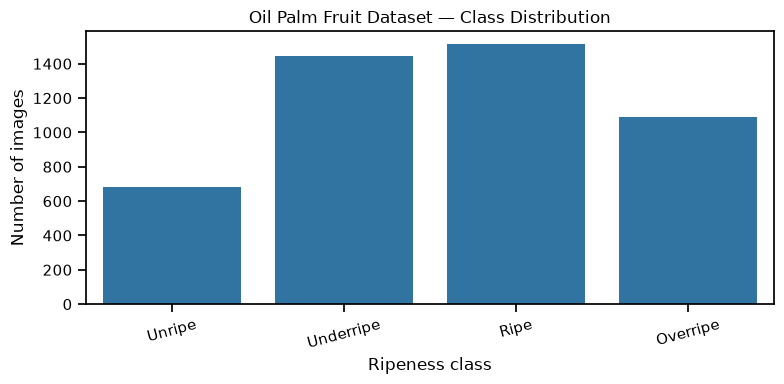

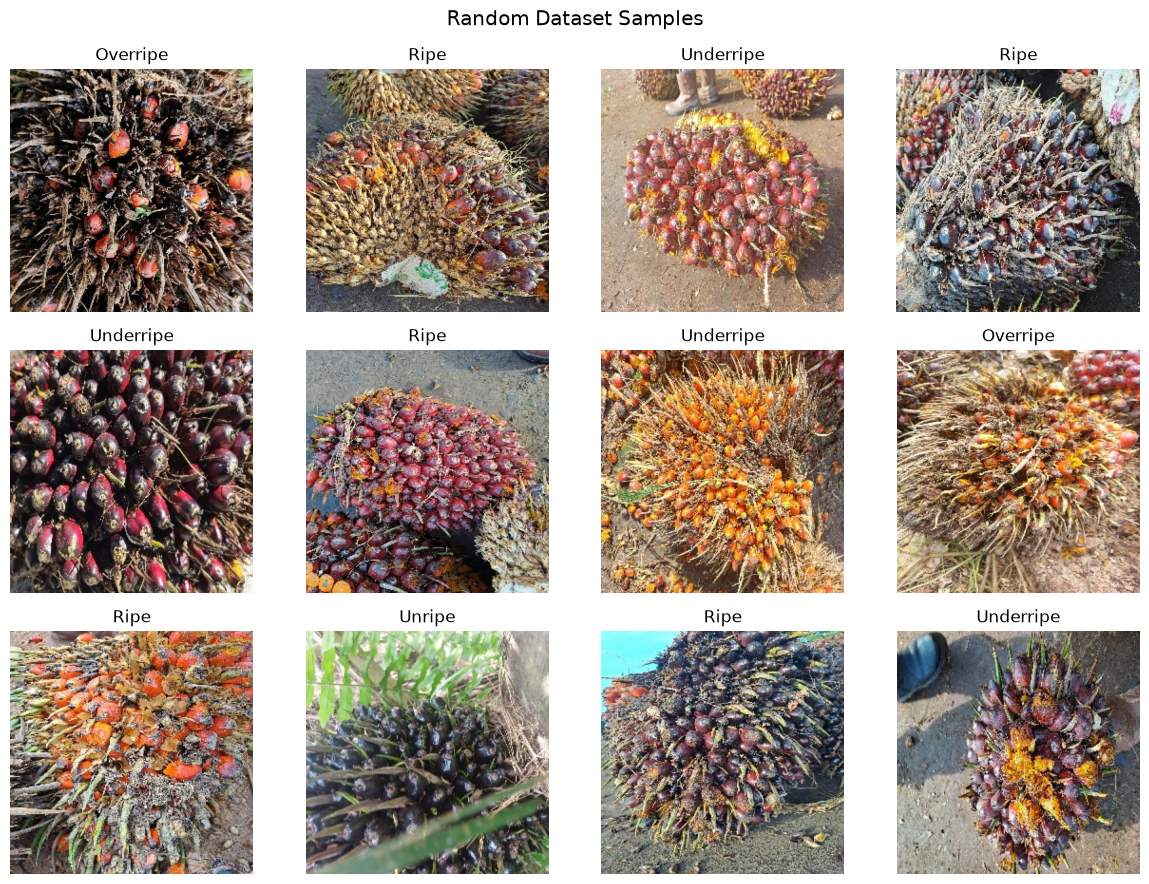

In [35]:
# Dataset distribution visualization.
counts = df["label"].value_counts().reindex(CLASS_NAMES_EXPECTED)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set_title("Oil Palm Fruit Dataset — Class Distribution")
ax.set_xlabel("Ripeness class"); ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

# Show random samples.
n_show = min(12, len(df))
sample_df = df.sample(n_show, random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, sample_df.to_dict("records")):
    try:
        im = Image.open(row["path"]).convert("RGB")
        ax.imshow(im); ax.set_title(row["label"]); ax.axis("off")
    except Exception as e:
        ax.set_title(f"Unreadable: {e}")
plt.suptitle("Random Dataset Samples")
plt.tight_layout(); plt.show()

In [36]:
# Verify image readability and dimensions.
valid_rows, bad_rows = [], []
for row in tqdm(df.to_dict("records"), desc="Checking images"):
    try:
        with Image.open(row["path"]) as im:
            im.verify()
        with Image.open(row["path"]) as im:
            w, h = im.size
        row["width"], row["height"] = w, h
        valid_rows.append(row)
    except Exception as e:
        bad_rows.append({"path": row["path"], "error": str(e)})

df = pd.DataFrame(valid_rows).reset_index(drop=True)
bad_df = pd.DataFrame(bad_rows)
print("Readable:", len(df), "| Unreadable:", len(bad_df))
if len(bad_df):
    display(bad_df.head())
display(df[["width", "height"]].describe())

Checking images: 100%|██████████| 4727/4727 [00:05<00:00, 913.86it/s] 

Readable: 4727 | Unreadable: 0


,width,height
count,4727.0,4727.0
mean,640.0,640.0
std,0.0,0.0
min,640.0,640.0
25%,640.0,640.0
50%,640.0,640.0
75%,640.0,640.0
max,640.0,640.0


In [37]:
# Exact duplicate audit using SHA-256.
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk: break
            h.update(chunk)
    return h.hexdigest()

df["sha256"] = [sha256_file(p) for p in tqdm(df["path"], desc="Hashing images")]
dup_mask = df.duplicated("sha256", keep=False)
duplicate_df = df.loc[dup_mask].sort_values("sha256")
print("Images participating in exact-duplicate groups:", int(dup_mask.sum()))
print("Unique exact hashes:", df["sha256"].nunique())
if len(duplicate_df):
    display(duplicate_df[["path", "label", "source_split", "sha256"]].head(20))

# Flag conflicting labels for identical image bytes.
conflict_hashes = (
    df.groupby("sha256")["label"].nunique().loc[lambda x: x > 1].index.tolist()
)
print("Exact duplicate hashes with conflicting labels:", len(conflict_hashes))

Hashing images: 100%|██████████| 4727/4727 [00:05<00:00, 872.47it/s] 

Images participating in exact-duplicate groups: 0
Unique exact hashes: 4727
Exact duplicate hashes with conflicting labels: 0


In [38]:
# Group identical files together, then make a reproducible group-aware split.
# Approximate target proportions: 70% train, 15% validation, 15% test.
# Group-level stratification is preferable to image-level random splitting.
from sklearn.model_selection import StratifiedGroupKFold

df["group_id"] = df["sha256"]
sgkf_test = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
all_idx = np.arange(len(df))
y = df["target"].values
groups = df["group_id"].values

# First hold out one fifth for test, then split remaining data into train/validation.
trainval_idx, test_idx = next(sgkf_test.split(all_idx, y, groups))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)

sgkf_val = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED + 1)
tr_rel, val_rel = next(sgkf_val.split(
    np.arange(len(trainval_df)),
    trainval_df["target"].values,
    trainval_df["group_id"].values
))
train_df = trainval_df.iloc[tr_rel].copy().reset_index(drop=True)
val_df = trainval_df.iloc[val_rel].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

# Explicitly verify group disjointness.
assert set(train_df.group_id).isdisjoint(set(val_df.group_id))
assert set(train_df.group_id).isdisjoint(set(test_df.group_id))
assert set(val_df.group_id).isdisjoint(set(test_df.group_id))

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(train_df), len(val_df), len(test_df)]
})
split_summary["percentage"] = 100 * split_summary["images"] / len(df)
display(split_summary)

,split,images,percentage
0,train,3375,71.398350
1,validation,676,14.300825
2,test,676,14.300825


In [39]:
# Check class coverage and split distribution. Review before training.
split_counts = pd.concat([
    train_df.assign(split="Train"),
    val_df.assign(split="Validation"),
    test_df.assign(split="Test")
]).pivot_table(index="label", columns="split", values="path", aggfunc="count", fill_value=0)
split_counts = split_counts.reindex(CLASS_NAMES_EXPECTED)
display(split_counts)

missing = {s: split_counts.columns[split_counts.loc[c] == 0].tolist()
           for c in split_counts.index for s in []}
assert (split_counts > 0).all().all(), (
    "At least one class is absent from a split. Revisit split strategy or collect more data."
)

split,Test,Train,Validation
label,,,
Unripe,97,487,98
Underripe,207,1032,206
Ripe,216,1080,217
Overripe,156,776,155


### Data transforms

Training augmentation is deliberately moderate. Validation/test use deterministic resizing and normalization only. ImageNet normalization is used for the pretrained MobileNetV2 branch; the same normalization is used consistently across all models.

In [40]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.12, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class PalmImageDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(row["target"])

train_ds = PalmImageDataset(train_df, train_transform)
val_ds = PalmImageDataset(val_df, eval_transform)
test_ds = PalmImageDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
                          persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

xb, yb = next(iter(train_loader))
print("Batch image tensor:", xb.shape, "| labels:", yb.shape)

Batch image tensor: torch.Size([16, 3, 224, 224]) | labels: torch.Size([16])


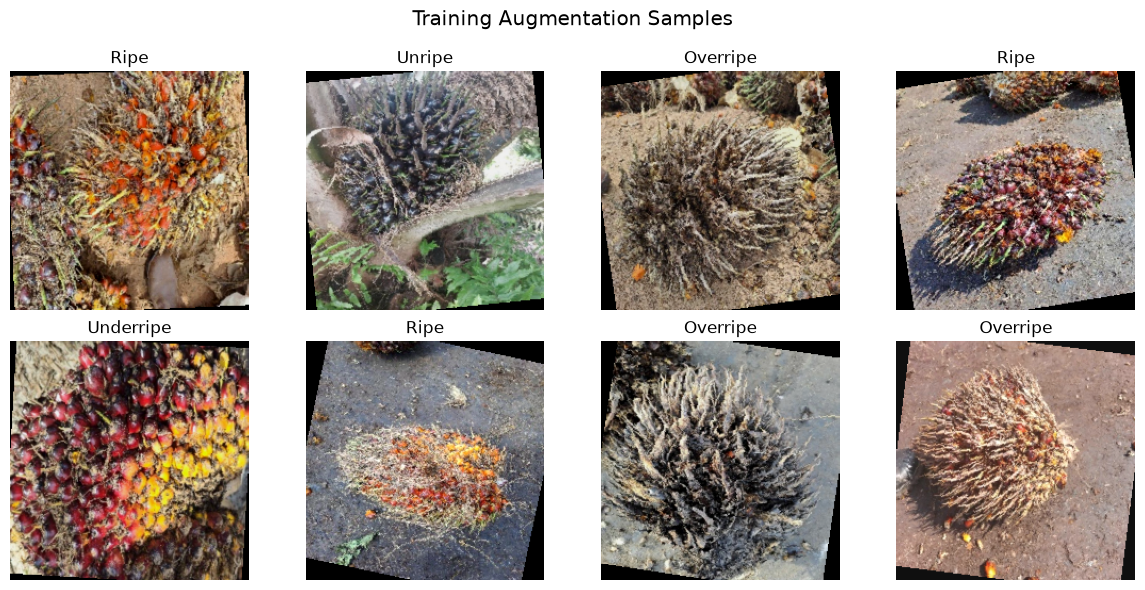

In [41]:
# Visualize normalized training examples after inverse normalization.
def denormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std = torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t.cpu() * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(denormalize(xb[i]).permute(1,2,0).numpy())
    ax.set_title(CLASS_NAMES_EXPECTED[int(yb[i])]); ax.axis("off")
plt.suptitle("Training Augmentation Samples")
plt.tight_layout(); plt.show()

## Part 2 — Shared training and evaluation utilities

In [42]:
from torch.cuda.amp import autocast, GradScaler

def make_scaler():
    # Compatible with older PyTorch versions.
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return GradScaler(enabled=USE_AMP)

def get_logits(output):
    # Models may return logits or a dictionary/tuple with logits.
    if isinstance(output, dict):
        return output["logits"]
    if isinstance(output, (tuple, list)):
        return output[0]
    return output

def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total_loss, all_y, all_pred = 0.0, [], []
    for images, labels in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=USE_AMP):
            output = model(images)
            logits = get_logits(output)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * labels.size(0)
        all_y.extend(labels.detach().cpu().numpy())
        all_pred.extend(logits.detach().argmax(1).cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(all_y, all_pred)

@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    total_loss, all_y, all_pred = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        with autocast(enabled=USE_AMP):
            logits = get_logits(model(images))
            loss = criterion(logits, labels)
        total_loss += loss.item() * labels.size(0)
        all_y.extend(labels.cpu().numpy())
        all_pred.extend(logits.argmax(1).cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(all_y, all_pred)

def fit_model(model, name, epochs=EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = make_scaler()
    history = []
    best_val_loss, best_state, bad_epochs = float("inf"), None, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, scaler)
        va_loss, va_acc = evaluate_loss_acc(model, val_loader, criterion)
        scheduler.step()
        history.append({
            "epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
            "val_loss": va_loss, "val_acc": va_acc,
            "lr": optimizer.param_groups[0]["lr"]
        })
        print(f"{name} | Epoch {epoch:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}")

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("Early stopping.")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    elapsed = time.time() - start
    hist = pd.DataFrame(history)
    hist.to_csv(OUTPUT_ROOT / f"{name}_history.csv", index=False)
    torch.save(model.state_dict(), MODEL_ROOT / f"{name}.pth")
    return model, hist, elapsed

def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist.epoch, hist.train_loss, label="Train")
    axes[0].plot(hist.epoch, hist.val_loss, label="Validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(hist.epoch, hist.train_acc, label="Train")
    axes[1].plot(hist.epoch, hist.val_acc, label="Validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    logits_all, y_all = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        with autocast(enabled=USE_AMP):
            out = model(x)
            logits = get_logits(out)
        logits_all.append(logits.float().cpu())
        y_all.append(y.cpu())
    return torch.cat(logits_all), torch.cat(y_all)

def classification_metrics(y_true, logits):
    probs = torch.softmax(logits, dim=1).numpy()
    pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true.numpy(), pred, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true.numpy(), pred),
        "balanced_accuracy": balanced_accuracy_score(y_true.numpy(), pred),
        "macro_precision": p, "macro_recall": r, "macro_f1": f1,
        "cohen_kappa": cohen_kappa_score(y_true.numpy(), pred)
    }

def evaluate_model(model, name):
    logits, y_true = collect_logits(model, test_loader)
    metrics = classification_metrics(y_true, logits)
    print(name, metrics)
    print(classification_report(y_true.numpy(), logits.argmax(1).numpy(),
                                target_names=CLASS_NAMES_EXPECTED, zero_division=0))
    cm = confusion_matrix(y_true.numpy(), logits.argmax(1).numpy())
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES_EXPECTED, yticklabels=CLASS_NAMES_EXPECTED)
    plt.title(f"{name} — Test Confusion Matrix")
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()
    return metrics, logits, y_true

experiment_results = {}
trained_models = {}
histories = {}

## Part 3 — E1: MobileNetV2 baseline

In [ ]:
class MobileNetV2Classifier(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True, dropout=0.25):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        base = models.mobilenet_v2(weights=weights)
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(base.last_channel, num_classes)
    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(self.dropout(x))

e1_model, e1_hist, e1_time = fit_model(MobileNetV2Classifier(), "E1_MobileNetV2")
trained_models["E1"] = e1_model; histories["E1"] = e1_hist
plot_history(e1_hist, "E1 — MobileNetV2")
e1_metrics, e1_logits, y_test = evaluate_model(e1_model, "E1_MobileNetV2")
experiment_results["E1_MobileNetV2"] = {**e1_metrics, "training_time_sec": e1_time}

  0%|          | 0/211 [00:00<?, ?it/s]            

E1_MobileNetV2 | Epoch 01/20 | train loss 0.6389 acc 0.7647 | val loss 0.4349 acc 0.8417


  0%|          | 0/211 [00:00<?, ?it/s]          

E1_MobileNetV2 | Epoch 02/20 | train loss 0.3956 acc 0.8542 | val loss 0.3492 acc 0.8654


  0%|          | 0/211 [00:00<?, ?it/s]          

E1_MobileNetV2 | Epoch 03/20 | train loss 0.3060 acc 0.8880 | val loss 0.3109 acc 0.8891


... (7 outputs left out)

E1_MobileNetV2 | Epoch 07/20 | train loss 0.1492 acc 0.9446 | val loss 0.3035 acc 0.8950


  0%|          | 0/211 [00:00<?, ?it/s]          

E1_MobileNetV2 | Epoch 08/20 | train loss 0.1328 acc 0.9544 | val loss 0.2905 acc 0.9053


 44%|████▎     | 92/211 [03:03<02:50,  1.43s/it]

## Part 4 — E2: Lightweight Transformer baseline

  0%|          | 0/211 [00:00<?, ?it/s]          

E2_LightweightTransformer | Epoch 01/20 | train loss 1.2187 acc 0.4542 | val loss 1.0536 acc 0.5488


  0%|          | 0/211 [00:00<?, ?it/s]          

E2_LightweightTransformer | Epoch 02/20 | train loss 1.0010 acc 0.5606 | val loss 0.8620 acc 0.6464


  0%|          | 0/211 [00:00<?, ?it/s]          

E2_LightweightTransformer | Epoch 03/20 | train loss 0.9172 acc 0.6030 | val loss 0.8865 acc 0.6317


... (29 outputs left out)

E2_LightweightTransformer | Epoch 18/20 | train loss 0.4311 acc 0.8276 | val loss 0.4816 acc 0.8136


  0%|          | 0/211 [00:00<?, ?it/s]          

E2_LightweightTransformer | Epoch 19/20 | train loss 0.4188 acc 0.8361 | val loss 0.4739 acc 0.8210


E2_LightweightTransformer | Epoch 20/20 | train loss 0.4239 acc 0.8311 | val loss 0.4722 acc 0.8136


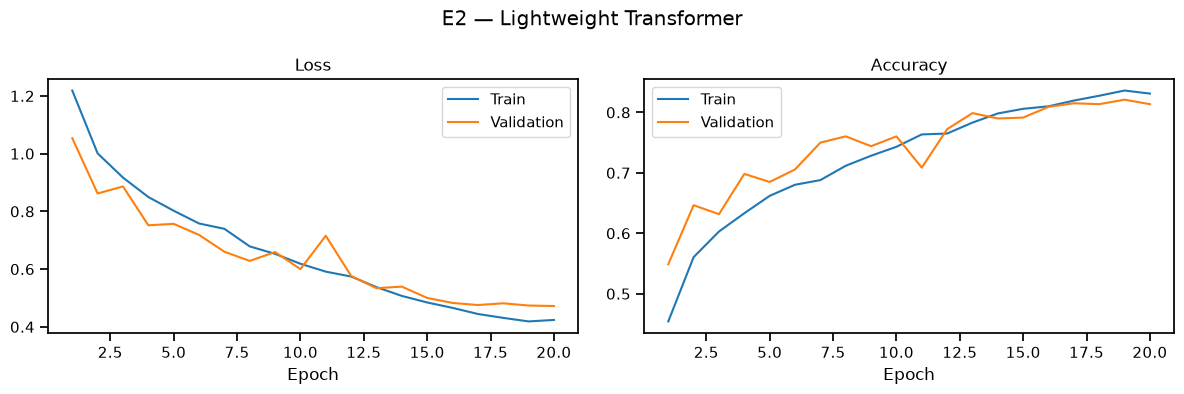

E2_LightweightTransformer {'accuracy': 0.8284023668639053, 'balanced_accuracy': 0.8394657608855278, 'macro_precision': 0.8359125124202849, 'macro_recall': 0.8394657608855278, 'macro_f1': 0.8376401641595721, 'cohen_kappa': 0.7652805881155638}
              precision    recall  f1-score   support

      Unripe       0.86      0.88      0.87        97
   Underripe       0.80      0.80      0.80       207
        Ripe       0.80      0.79      0.79       216
    Overripe       0.89      0.90      0.89       156

    accuracy                           0.83       676
   macro avg       0.84      0.84      0.84       676
weighted avg       0.83      0.83      0.83       676



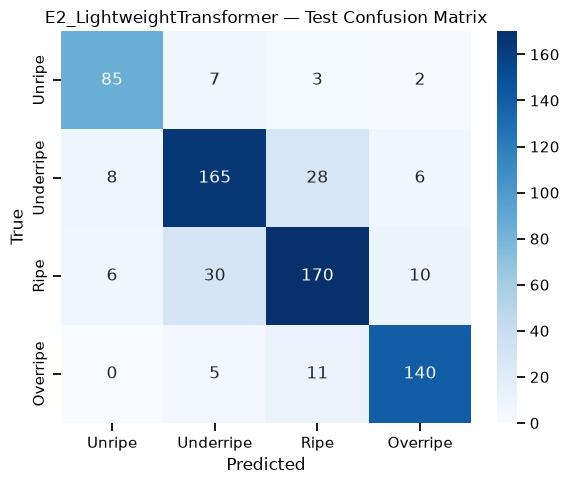

In [25]:
class ConvPatchEmbed(nn.Module):
    def __init__(self, in_ch=3, embed_dim=192, patch_size=16):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size, stride=patch_size)
    def forward(self, x):
        x = self.proj(x)
        return x.flatten(2).transpose(1, 2)

class LightweightVisionTransformer(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, embed_dim=192, depth=4, heads=3, dropout=0.1):
        super().__init__()
        self.patch = ConvPatchEmbed(embed_dim=embed_dim, patch_size=16)
        n_tokens = (IMAGE_SIZE // 16) ** 2
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_tokens + 1, embed_dim))
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=heads, dim_feedforward=embed_dim*4,
            dropout=dropout, batch_first=True, norm_first=True, activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
    def forward_features(self, x):
        x = self.patch(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1) + self.pos_embed
        x = self.encoder(x)
        return self.norm(x[:, 0])
    def forward(self, x):
        return self.head(self.forward_features(x))

e2_model, e2_hist, e2_time = fit_model(
    LightweightVisionTransformer(), "E2_LightweightTransformer", lr=LEARNING_RATE
)
trained_models["E2"] = e2_model; histories["E2"] = e2_hist
plot_history(e2_hist, "E2 — Lightweight Transformer")
e2_metrics, e2_logits, _ = evaluate_model(e2_model, "E2_LightweightTransformer")
experiment_results["E2_LightweightTransformer"] = {**e2_metrics, "training_time_sec": e2_time}

## Part 5 — E3: Hybrid CNN–Transformer baseline

  0%|          | 0/211 [00:00<?, ?it/s]          

E3_Hybrid | Epoch 01/20 | train loss 0.6747 acc 0.7256 | val loss 0.5121 acc 0.7929


  0%|          | 0/211 [00:00<?, ?it/s]          

E3_Hybrid | Epoch 02/20 | train loss 0.4407 acc 0.8382 | val loss 0.3498 acc 0.8787


  0%|          | 0/211 [00:00<?, ?it/s]          

E3_Hybrid | Epoch 03/20 | train loss 0.3231 acc 0.8791 | val loss 0.3526 acc 0.8787


... (17 outputs left out)

E3_Hybrid | Epoch 12/20 | train loss 0.0684 acc 0.9793 | val loss 0.2890 acc 0.9112


  0%|          | 0/211 [00:00<?, ?it/s]          

E3_Hybrid | Epoch 13/20 | train loss 0.0478 acc 0.9828 | val loss 0.3038 acc 0.9083


E3_Hybrid | Epoch 14/20 | train loss 0.0483 acc 0.9843 | val loss 0.2998 acc 0.9142
Early stopping.


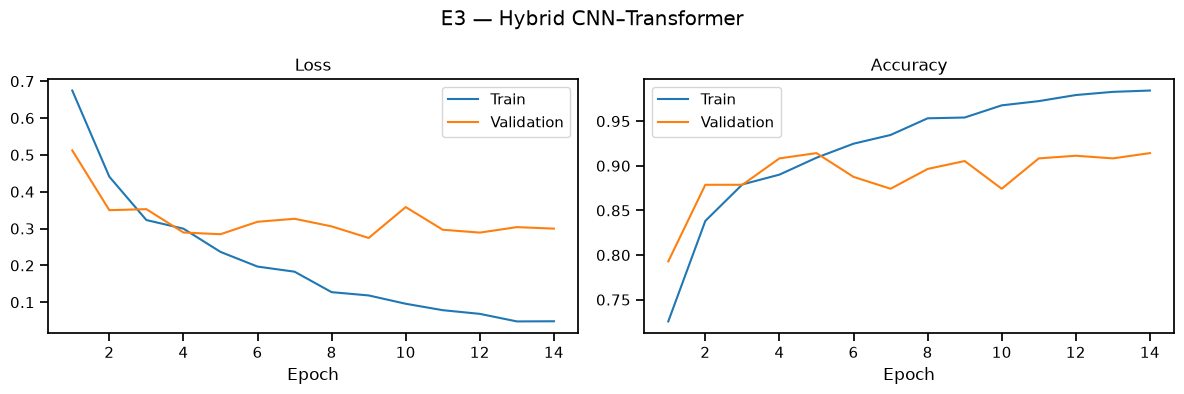

E3_Hybrid {'accuracy': 0.8905325443786982, 'balanced_accuracy': 0.9007452613458888, 'macro_precision': 0.9051901430744578, 'macro_recall': 0.9007452613458888, 'macro_f1': 0.9028102325269041, 'cohen_kappa': 0.8499233476237763}
              precision    recall  f1-score   support

      Unripe       0.97      0.95      0.96        97
   Underripe       0.87      0.85      0.86       207
        Ripe       0.84      0.88      0.86       216
    Overripe       0.94      0.93      0.94       156

    accuracy                           0.89       676
   macro avg       0.91      0.90      0.90       676
weighted avg       0.89      0.89      0.89       676



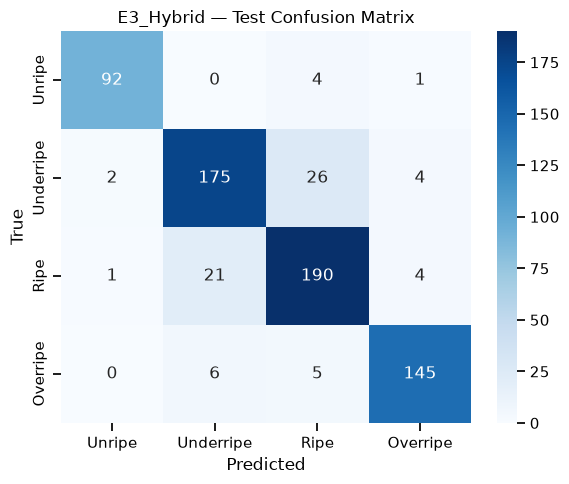

In [26]:
class HybridCNNTransformer(nn.Module):
    # E3: dual branch with simple equal-dimensional concatenation.
    def __init__(self, num_classes=NUM_CLASSES, cnn_pretrained=True, embed_dim=192):
        super().__init__()
        weights = models.MobileNet_V2_Weights.DEFAULT if cnn_pretrained else None
        base = models.mobilenet_v2(weights=weights)
        self.cnn = base.features
        self.cnn_pool = nn.AdaptiveAvgPool2d(1)
        self.cnn_proj = nn.Linear(base.last_channel, embed_dim)

        self.patch = ConvPatchEmbed(embed_dim=embed_dim, patch_size=16)
        n_tokens = (IMAGE_SIZE // 16) ** 2
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_tokens + 1, embed_dim))
        enc_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=3, dim_feedforward=embed_dim*4,
            dropout=0.1, batch_first=True, norm_first=True, activation="gelu"
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=2)
        self.trans_norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(0.25)
        self.classifier = nn.Linear(embed_dim * 2, num_classes)

    def extract_branches(self, x):
        c = self.cnn_pool(self.cnn(x)).flatten(1)
        c = self.cnn_proj(c)
        t = self.patch(x)
        cls = self.cls_token.expand(t.size(0), -1, -1)
        t = torch.cat([cls, t], dim=1) + self.pos_embed
        t = self.trans_norm(self.transformer(t)[:, 0])
        return c, t

    def forward(self, x):
        c, t = self.extract_branches(x)
        fused = torch.cat([c, t], dim=1)
        return self.classifier(self.dropout(fused))

e3_model, e3_hist, e3_time = fit_model(HybridCNNTransformer(), "E3_Hybrid", lr=LEARNING_RATE)
trained_models["E3"] = e3_model; histories["E3"] = e3_hist
plot_history(e3_hist, "E3 — Hybrid CNN–Transformer")
e3_metrics, e3_logits, _ = evaluate_model(e3_model, "E3_Hybrid")
experiment_results["E3_Hybrid"] = {**e3_metrics, "training_time_sec": e3_time}

## Part 6 — E4: Hybrid + conventional feature fusion

In [28]:
class ConventionalFusionModel(HybridCNNTransformer):
    # E4: concatenate branch features, then learn a projection/MLP fusion block.
    def __init__(self, num_classes=NUM_CLASSES, cnn_pretrained=True, embed_dim=192):
        super().__init__(num_classes, cnn_pretrained, embed_dim)
        self.fusion = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.LayerNorm(embed_dim),
            nn.GELU(),
            nn.Dropout(0.25)
        )
        self.classifier = nn.Linear(embed_dim, num_classes)
    def forward(self, x):
        c, t = self.extract_branches(x)
        fused = self.fusion(torch.cat([c, t], dim=1))
        return self.classifier(fused)

e4_model, e4_hist, e4_time = fit_model(
    ConventionalFusionModel(), "E4_ConventionalFusion", lr=LEARNING_RATE
)
trained_models["E4"] = e4_model; histories["E4"] = e4_hist
plot_history(e4_hist, "E4 — Conventional Feature Fusion")
e4_metrics, e4_logits, _ = evaluate_model(e4_model, "E4_ConventionalFusion")
experiment_results["E4_ConventionalFusion"] = {**e4_metrics, "training_time_sec": e4_time}

NameError: name 'HybridCNNTransformer' is not defined

## Part 7 — E5: Hybrid + uncertainty estimation

E5 estimates uncertainty from branch-specific auxiliary predictions but does **not** use uncertainty to control feature fusion. This isolates the value of uncertainty measurement from the proposed adaptive fusion mechanism.

In [ ]:
class UncertaintyHybridModel(HybridCNNTransformer):
    def __init__(self, num_classes=NUM_CLASSES, cnn_pretrained=True, embed_dim=192):
        super().__init__(num_classes, cnn_pretrained, embed_dim)
        self.cnn_aux = nn.Linear(embed_dim, num_classes)
        self.trans_aux = nn.Linear(embed_dim, num_classes)
    def forward(self, x, return_aux=False):
        c, t = self.extract_branches(x)
        fused_logits = self.classifier(self.dropout(torch.cat([c, t], dim=1)))
        if return_aux:
            return {
                "logits": fused_logits,
                "cnn_logits": self.cnn_aux(c),
                "transformer_logits": self.trans_aux(t),
                "cnn_features": c, "transformer_features": t
            }
        return fused_logits

def train_one_epoch_aux(model, loader, optimizer, scaler, aux_weight=0.3):
    model.train()
    criterion = nn.CrossEntropyLoss()
    total, ys, preds = 0.0, [], []
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=USE_AMP):
            out = model(x, return_aux=True)
            loss = (criterion(out["logits"], y) +
                    aux_weight * criterion(out["cnn_logits"], y) +
                    aux_weight * criterion(out["transformer_logits"], y))
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total += loss.item() * y.size(0)
        ys.extend(y.cpu().numpy()); preds.extend(out["logits"].argmax(1).detach().cpu().numpy())
    return total / len(loader.dataset), accuracy_score(ys, preds)

@torch.no_grad()
def eval_aux(model, loader):
    model.eval()
    total, ys, preds = 0.0, [], []
    criterion = nn.CrossEntropyLoss()
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x, return_aux=True)
        total += criterion(out["logits"], y).item() * y.size(0)
        ys.extend(y.cpu().numpy()); preds.extend(out["logits"].argmax(1).cpu().numpy())
    return total / len(loader.dataset), accuracy_score(ys, preds)

def fit_aux_model(model, name, epochs=EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = make_scaler()
    hist, best_loss, best_state, bad, start = [], float("inf"), None, 0, time.time()
    for ep in range(1, epochs+1):
        tr_l, tr_a = train_one_epoch_aux(model, train_loader, opt, scaler)
        va_l, va_a = eval_aux(model, val_loader)
        sched.step()
        hist.append({"epoch":ep,"train_loss":tr_l,"train_acc":tr_a,"val_loss":va_l,"val_acc":va_a})
        print(f"{name} | {ep}/{epochs} | train {tr_l:.4f}/{tr_a:.4f} | val {va_l:.4f}/{va_a:.4f}")
        if va_l < best_loss:
            best_loss = va_l
            best_state = copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
            if bad >= patience: break
    if best_state: model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.to_csv(OUTPUT_ROOT/f"{name}_history.csv", index=False)
    torch.save(model.state_dict(), MODEL_ROOT/f"{name}.pth")
    return model, hist, time.time()-start

e5_model, e5_hist, e5_time = fit_aux_model(UncertaintyHybridModel(), "E5_Uncertainty")
trained_models["E5"] = e5_model; histories["E5"] = e5_hist
plot_history(e5_hist, "E5 — Hybrid with Uncertainty Estimation")
e5_metrics, e5_logits, _ = evaluate_model(e5_model, "E5_Uncertainty")
experiment_results["E5_Uncertainty"] = {**e5_metrics, "training_time_sec": e5_time}

In [ ]:
# Branch-specific predictive entropy for E5.
@torch.no_grad()
def collect_aux_outputs(model, loader):
    model.eval()
    outputs = defaultdict(list); ys = []
    for x, y in loader:
        x = x.to(DEVICE)
        out = model(x, return_aux=True)
        for k in ["logits", "cnn_logits", "transformer_logits"]:
            outputs[k].append(out[k].float().cpu())
        ys.append(y)
    return {k: torch.cat(v) for k,v in outputs.items()}, torch.cat(ys)

def entropy_from_logits(logits, eps=1e-8):
    p = torch.softmax(logits, dim=1).clamp_min(eps)
    return -(p * p.log()).sum(dim=1)

e5_outputs, y_test_e5 = collect_aux_outputs(e5_model, test_loader)
e5_uc = entropy_from_logits(e5_outputs["cnn_logits"])
e5_ut = entropy_from_logits(e5_outputs["transformer_logits"])
fig, ax = plt.subplots(figsize=(8,4))
sns.kdeplot(e5_uc.numpy(), label="CNN branch entropy", ax=ax)
sns.kdeplot(e5_ut.numpy(), label="Transformer branch entropy", ax=ax)
ax.set_title("E5 — Branch Predictive Entropy"); ax.set_xlabel("Entropy (nats)")
ax.legend(); plt.tight_layout(); plt.show()

## Part 8 — E6: Proposed Uncertainty-Conditioned Feature Fusion (UC-DFF)

**Proposed mechanism (initial version):** each branch produces an auxiliary class distribution. Its predictive entropy estimates branch uncertainty. A softmax over negative branch entropies generates adaptive reliability weights. The weighted branch features are fused and classified.

\[
U_b(x)=-\sum_{k=1}^{K}p_{b,k}(x)\log(p_{b,k}(x)),\quad b\in\{c,t\}
\]

\[
[w_c,w_t]=\operatorname{softmax}([-U_c,-U_t]/\tau)
\]

\[
F(x)=\operatorname{Concat}(w_cF_c,w_tF_t)
\]

This is a testable proposed mechanism, not a proven novelty claim. We will compare it with E3/E4 and ablate the uncertainty weighting. Entropy alone can be affected by calibration and branch logit scale, so temperature calibration and validation-only analysis are required.

In [ ]:
class UCFFModel(HybridCNNTransformer):
    def __init__(self, num_classes=NUM_CLASSES, cnn_pretrained=True, embed_dim=192, tau=1.0):
        super().__init__(num_classes, cnn_pretrained, embed_dim)
        self.cnn_aux = nn.Linear(embed_dim, num_classes)
        self.trans_aux = nn.Linear(embed_dim, num_classes)
        self.fusion_norm = nn.LayerNorm(embed_dim * 2)
        self.head = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim),
            nn.GELU(), nn.Dropout(0.25),
            nn.Linear(embed_dim, num_classes)
        )
        self.tau = tau

    def forward(self, x, return_details=False):
        c, t = self.extract_branches(x)
        lc, lt = self.cnn_aux(c), self.trans_aux(t)
        pc = torch.softmax(lc, dim=1).clamp_min(1e-8)
        pt = torch.softmax(lt, dim=1).clamp_min(1e-8)
        uc = -(pc * pc.log()).sum(dim=1, keepdim=True)
        ut = -(pt * pt.log()).sum(dim=1, keepdim=True)
        weights = torch.softmax(torch.cat([-uc, -ut], dim=1) / self.tau, dim=1)
        fused = torch.cat([weights[:, 0:1] * c, weights[:, 1:2] * t], dim=1)
        logits = self.head(self.fusion_norm(fused))
        if return_details:
            return {
                "logits": logits, "cnn_logits": lc, "transformer_logits": lt,
                "cnn_uncertainty": uc, "transformer_uncertainty": ut,
                "fusion_weights": weights, "cnn_features": c, "transformer_features": t
            }
        return logits

def train_one_epoch_ucff(model, loader, optimizer, scaler, aux_weight=0.3):
    model.train()
    ce = nn.CrossEntropyLoss()
    total, ys, preds = 0.0, [], []
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=USE_AMP):
            out = model(x, return_details=True)
            loss = (ce(out["logits"], y) +
                    aux_weight * ce(out["cnn_logits"], y) +
                    aux_weight * ce(out["transformer_logits"], y))
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total += loss.item() * y.size(0)
        ys.extend(y.cpu().numpy()); preds.extend(out["logits"].argmax(1).detach().cpu().numpy())
    return total/len(loader.dataset), accuracy_score(ys, preds)

@torch.no_grad()
def eval_ucff(model, loader):
    model.eval()
    ce = nn.CrossEntropyLoss()
    total, ys, preds = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x, return_details=True)
        total += ce(out["logits"], y).item() * y.size(0)
        ys.extend(y.cpu().numpy()); preds.extend(out["logits"].argmax(1).cpu().numpy())
    return total/len(loader.dataset), accuracy_score(ys, preds)

def fit_ucff(model, name, epochs=EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = make_scaler()
    hist, best_loss, best_state, bad, start = [], float("inf"), None, 0, time.time()
    for ep in range(1, epochs+1):
        tr_l, tr_a = train_one_epoch_ucff(model, train_loader, opt, scaler)
        va_l, va_a = eval_ucff(model, val_loader)
        sched.step()
        hist.append({"epoch":ep,"train_loss":tr_l,"train_acc":tr_a,"val_loss":va_l,"val_acc":va_a})
        print(f"{name} | {ep}/{epochs} | train {tr_l:.4f}/{tr_a:.4f} | val {va_l:.4f}/{va_a:.4f}")
        if va_l < best_loss:
            best_loss = va_l
            best_state = copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
            if bad >= patience: break
    if best_state: model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.to_csv(OUTPUT_ROOT/f"{name}_history.csv", index=False)
    torch.save(model.state_dict(), MODEL_ROOT/f"{name}.pth")
    return model, hist, time.time()-start

e6_model, e6_hist, e6_time = fit_ucff(UCFFModel(), "E6_Proposed_UCFF")
trained_models["E6"] = e6_model; histories["E6"] = e6_hist
plot_history(e6_hist, "E6 — Proposed UC-DFF")
e6_metrics, e6_logits, _ = evaluate_model(e6_model, "E6_Proposed_UCFF")
experiment_results["E6_Proposed_UCFF"] = {**e6_metrics, "training_time_sec": e6_time}

In [ ]:
# Visualize E6 branch uncertainties and adaptive fusion weights.
@torch.no_grad()
def collect_ucff_details(model, loader):
    model.eval()
    out_all = defaultdict(list); ys = []
    for x, y in loader:
        out = model(x.to(DEVICE), return_details=True)
        for k in ["logits","cnn_uncertainty","transformer_uncertainty","fusion_weights"]:
            out_all[k].append(out[k].float().cpu())
        ys.append(y)
    return {k:torch.cat(v) for k,v in out_all.items()}, torch.cat(ys)

e6_details, y_test_e6 = collect_ucff_details(e6_model, test_loader)
weights = e6_details["fusion_weights"].numpy()
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(e6_details["cnn_uncertainty"].numpy().ravel(), bins=25, alpha=0.7, label="CNN")
axes[0].hist(e6_details["transformer_uncertainty"].numpy().ravel(), bins=25, alpha=0.7, label="Transformer")
axes[0].set_title("E6 Branch Uncertainty"); axes[0].set_xlabel("Entropy"); axes[0].legend()
axes[1].boxplot([weights[:,0], weights[:,1]], labels=["CNN weight","Transformer weight"])
axes[1].set_title("E6 Adaptive Fusion Weights"); axes[1].set_ylabel("Weight")
plt.tight_layout(); plt.show()
print("Mean fusion weights — CNN:", weights[:,0].mean(), "| Transformer:", weights[:,1].mean())

## Part 9 — Calibration and uncertainty metrics

In [ ]:
def expected_calibration_error(logits, labels, n_bins=15):
    probs = torch.softmax(logits, dim=1)
    conf, pred = probs.max(dim=1)
    correct = pred.eq(labels)
    ece = torch.zeros(1)
    bins = torch.linspace(0, 1, n_bins + 1)
    for i in range(n_bins):
        mask = (conf > bins[i]) & (conf <= bins[i+1])
        if mask.any():
            acc_bin = correct[mask].float().mean()
            conf_bin = conf[mask].mean()
            ece += mask.float().mean() * torch.abs(acc_bin - conf_bin)
    return float(ece.item())

def brier_score_multiclass(logits, labels, num_classes=NUM_CLASSES):
    probs = torch.softmax(logits, dim=1)
    onehot = F.one_hot(labels, num_classes=num_classes).float()
    return float(torch.mean(torch.sum((probs-onehot)**2, dim=1)).item())

def nll_score(logits, labels):
    return float(F.cross_entropy(logits, labels).item())

def reliability_plot(logits, labels, n_bins=15, title="Reliability Diagram"):
    probs = torch.softmax(logits, dim=1)
    conf, pred = probs.max(dim=1)
    correct = pred.eq(labels)
    bins = torch.linspace(0, 1, n_bins+1)
    bin_conf, bin_acc = [], []
    for i in range(n_bins):
        mask = (conf > bins[i]) & (conf <= bins[i+1])
        if mask.any():
            bin_conf.append(conf[mask].mean().item())
            bin_acc.append(correct[mask].float().mean().item())
    plt.figure(figsize=(5,5))
    plt.plot([0,1],[0,1],"--",label="Perfect calibration")
    plt.plot(bin_conf,bin_acc,"o-",label="Model")
    plt.xlabel("Mean confidence"); plt.ylabel("Accuracy")
    plt.title(title); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

calibration_rows = []
for name, logits in [
    ("E1", e1_logits), ("E2", e2_logits), ("E3", e3_logits),
    ("E4", e4_logits), ("E5", e5_logits), ("E6", e6_logits)
]:
    calibration_rows.append({
        "model": name,
        "ECE": expected_calibration_error(logits, y_test),
        "Brier": brier_score_multiclass(logits, y_test),
        "NLL": nll_score(logits, y_test)
    })
calibration_df = pd.DataFrame(calibration_rows)
display(calibration_df)
reliability_plot(e6_logits, y_test, title="E6 — Reliability Diagram")

## Part 10 — Model efficiency

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def measure_latency(model, loader, warmup=10, max_batches=30):
    model.eval()
    sample_x, _ = next(iter(loader))
    sample_x = sample_x[:min(BATCH_SIZE, len(sample_x))].to(DEVICE)
    for _ in range(warmup):
        _ = model(sample_x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    times = []
    for i, (x, _) in enumerate(loader):
        if i >= max_batches: break
        x = x.to(DEVICE)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        _ = model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        times.append((time.perf_counter()-t0)/len(x))
    return float(np.mean(times)*1000)

eff_rows = []
for key, model in trained_models.items():
    model.eval()
    eff_rows.append({
        "experiment": key,
        "trainable_parameters": count_parameters(model),
        "latency_ms_per_image": measure_latency(model, test_loader),
    })
efficiency_df = pd.DataFrame(eff_rows)
display(efficiency_df)

## Part 11 — Final comparative analysis

In [ ]:
comparison_rows = []
for name, metrics in experiment_results.items():
    comparison_rows.append({"model": name, **metrics})
comparison_df = pd.DataFrame(comparison_rows)
if len(comparison_df):
    display(comparison_df.sort_values("macro_f1", ascending=False).reset_index(drop=True))

# Merge calibration and efficiency tables.
final_table = comparison_df.merge(
    calibration_df, left_on="model", right_on="model", how="left"
) if len(comparison_df) else pd.DataFrame()
# Model key names differ from calibration labels; map explicitly.
if len(comparison_df):
    cal_map = {"E1_MobileNetV2":"E1","E2_LightweightTransformer":"E2",
               "E3_Hybrid":"E3","E4_ConventionalFusion":"E4",
               "E5_Uncertainty":"E5","E6_Proposed_UCFF":"E6"}
    comparison_df["short_name"] = comparison_df["model"].map(cal_map)
    final_table = comparison_df.merge(calibration_df, left_on="short_name", right_on="model",
                                      suffixes=("", "_cal")).drop(columns=["model_cal"])
    final_table = final_table.merge(efficiency_df, left_on="short_name", right_on="experiment",
                                    how="left").drop(columns=["experiment"])
    display(final_table)

In [ ]:
# Comparative charts.
if len(comparison_df):
    plot_df = comparison_df.copy()
    plot_df["short_name"] = plot_df["model"].map({
        "E1_MobileNetV2":"E1","E2_LightweightTransformer":"E2",
        "E3_Hybrid":"E3","E4_ConventionalFusion":"E4",
        "E5_Uncertainty":"E5","E6_Proposed_UCFF":"E6"
    })
    fig, axes = plt.subplots(1, 2, figsize=(13,4))
    sns.barplot(data=plot_df, x="short_name", y="accuracy", ax=axes[0])
    axes[0].set_title("Test Accuracy"); axes[0].set_ylim(0,1)
    sns.barplot(data=plot_df, x="short_name", y="macro_f1", ax=axes[1])
    axes[1].set_title("Test Macro-F1"); axes[1].set_ylim(0,1)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(8,4))
    sns.barplot(data=calibration_df, x="model", y="ECE", ax=ax)
    ax.set_title("Expected Calibration Error (lower is better)")
    plt.tight_layout(); plt.show()

## Part 12 — Robustness evaluation (optional but recommended)

This section applies controlled corruptions to the held-out test images. These are **synthetic robustness tests**, not external-domain validation. Do not describe them as cross-domain generalization.

In [ ]:
from PIL import ImageEnhance, ImageFilter

class CorruptedPalmDataset(Dataset):
    def __init__(self, frame, corruption="brightness", severity=1):
        self.frame = frame.reset_index(drop=True)
        self.corruption = corruption
        self.severity = severity
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        im = Image.open(row["path"]).convert("RGB")
        s = self.severity
        if self.corruption == "brightness":
            im = ImageEnhance.Brightness(im).enhance(1.0 + 0.2*s)
        elif self.corruption == "contrast":
            im = ImageEnhance.Contrast(im).enhance(max(0.2, 1.0 - 0.15*s))
        elif self.corruption == "blur":
            im = im.filter(ImageFilter.GaussianBlur(radius=0.5*s))
        elif self.corruption == "color":
            im = ImageEnhance.Color(im).enhance(max(0.1, 1.0 - 0.2*s))
        x = eval_transform(im)
        return x, int(row["target"])

@torch.no_grad()
def evaluate_loader_simple(model, loader):
    model.eval(); ys=[]; ps=[]
    for x,y in loader:
        logits = model(x.to(DEVICE))
        ys.extend(y.numpy()); ps.extend(logits.argmax(1).cpu().numpy())
    return accuracy_score(ys,ps), precision_recall_fscore_support(ys,ps,average="macro",zero_division=0)[2]

robust_rows = []
for corruption in ["brightness","contrast","blur","color"]:
    for severity in [1,2,3]:
        ds = CorruptedPalmDataset(test_df, corruption, severity)
        loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
        for key in ["E3","E4","E5","E6"]:
            acc, f1 = evaluate_loader_simple(trained_models[key], loader)
            robust_rows.append({"corruption":corruption,"severity":severity,
                                "model":key,"accuracy":acc,"macro_f1":f1})
robust_df = pd.DataFrame(robust_rows)
display(robust_df.head())

In [ ]:
# Robustness visualization.
if "robust_df" in globals() and len(robust_df):
    g = sns.relplot(data=robust_df, x="severity", y="macro_f1",
                    hue="model", col="corruption", kind="line",
                    marker="o", col_wrap=2, height=3.5, facet_kws={"sharey":True})
    g.set_axis_labels("Corruption severity", "Macro-F1")
    g.fig.suptitle("Synthetic Robustness Evaluation", y=1.03)
    plt.show()

## Part 13 — Ablation study for UC-DFF

Ablation must isolate the effect of uncertainty-conditioned weighting. Recommended variants:
1. Equal weighting: \(w_c=w_t=0.5\).
2. Learned conventional fusion (E4).
3. Entropy-based UC-DFF (E6).
4. Optional calibrated entropy: temperature-scale branch logits using validation data only, then recompute weights.

The following cell summarizes the currently trained E3/E4/E6 comparison. For a publication-grade ablation, implement and train each ablation variant under the same protocol and multiple seeds.

In [ ]:
ablation_summary = comparison_df[comparison_df["model"].isin(
    ["E3_Hybrid","E4_ConventionalFusion","E6_Proposed_UCFF"]
)].copy() if len(comparison_df) else pd.DataFrame()
display(ablation_summary)

## Part 14 — Statistical analysis and reproducibility

In [ ]:
# Bootstrap confidence interval for test accuracy and Macro-F1.
def bootstrap_metric_ci(y_true, logits, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    y = y_true.numpy()
    pred = logits.argmax(1).numpy()
    accs, f1s = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        accs.append(accuracy_score(y[idx], pred[idx]))
        f1s.append(precision_recall_fscore_support(
            y[idx], pred[idx], average="macro", zero_division=0
        )[2])
    return {
        "accuracy_ci_low": float(np.percentile(accs, 2.5)),
        "accuracy_ci_high": float(np.percentile(accs, 97.5)),
        "macro_f1_ci_low": float(np.percentile(f1s, 2.5)),
        "macro_f1_ci_high": float(np.percentile(f1s, 97.5)),
    }

ci_rows = []
for name, logits in [("E1",e1_logits),("E2",e2_logits),("E3",e3_logits),
                     ("E4",e4_logits),("E5",e5_logits),("E6",e6_logits)]:
    ci_rows.append({"model":name, **bootstrap_metric_ci(y_test, logits)})
ci_df = pd.DataFrame(ci_rows)
display(ci_df)

In [ ]:
# Save key results and configuration.
config = {
    "seed": SEED, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
    "epochs_max": EPOCHS, "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "device": str(DEVICE),
    "classes": CLASS_NAMES_EXPECTED, "dataset_root": str(DATA_ROOT.resolve()),
    "split_counts": {"train":len(train_df),"validation":len(val_df),"test":len(test_df)}
}
with open(OUTPUT_ROOT/"experiment_config.json","w") as f:
    json.dump(config, f, indent=2)

if len(comparison_df):
    comparison_df.to_csv(OUTPUT_ROOT/"comparison_metrics.csv", index=False)
if len(calibration_df):
    calibration_df.to_csv(OUTPUT_ROOT/"calibration_metrics.csv", index=False)
if len(efficiency_df):
    efficiency_df.to_csv(OUTPUT_ROOT/"efficiency_metrics.csv", index=False)
if "robust_df" in globals():
    robust_df.to_csv(OUTPUT_ROOT/"robustness_metrics.csv", index=False)
ci_df.to_csv(OUTPUT_ROOT/"bootstrap_confidence_intervals.csv", index=False)

print("Saved outputs to:", OUTPUT_ROOT.resolve())
print("Saved model weights to:", MODEL_ROOT.resolve())

## Final research checklist

Before using results in a manuscript, verify all items:

- [ ] Dataset source, version, license, download date, and class definitions are recorded.
- [ ] Exact and near-duplicate image audit is completed; groups do not cross splits.
- [ ] Split proportions and per-class counts are reported.
- [ ] Test set is untouched during model selection and calibration.
- [ ] Every experiment uses the same split and evaluation code.
- [ ] E1–E6 are repeated across multiple random seeds for robust claims.
- [ ] E6 is compared against equal fusion, conventional fusion, and uncertainty-only controls.
- [ ] Calibration is fitted on validation data only, never on test data.
- [ ] Robustness tests are described as synthetic corruption tests, not cross-domain tests.
- [ ] Parameter count, latency, memory use, and training cost are reported.
- [ ] All reported results are generated by notebook execution, not manually entered.

**Important methodological note:** the current notebook is a complete experimental scaffold and first-pass implementation. The initial UC-DFF uses branch predictive entropy as its uncertainty proxy. Before claiming a novel uncertainty method, we must validate calibration, compare alternative uncertainty estimators, run repeated-seed experiments, and verify the novelty against current literature.